# LLN and CLT for Bernoulli samples

The weak law of large numbers (running mean converges in probability to
the expectation) and the central limit theorem (the properly rescaled
sum tends to a standard normal), illustrated on i.i.d. Bernoulli$(p)$ draws.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(0)

## 1. LLN: running mean converges to $p$

For $X_i \sim \mathrm{Bernoulli}(p)$ i.i.d., the running mean
$\bar X_n = \frac{1}{n} \sum_{i=1}^n X_i$ converges to $p$ in probability.

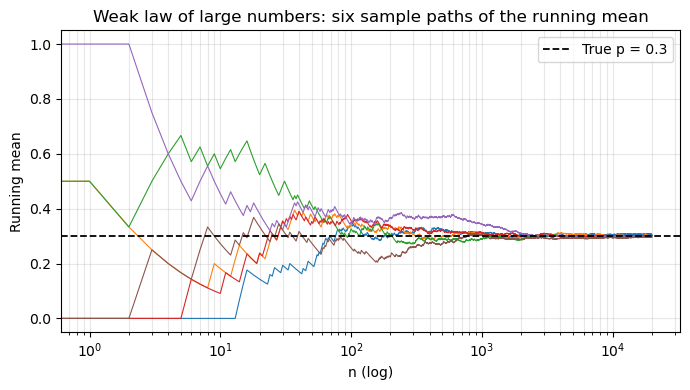

In [2]:
p = 0.3
N = 20_000
n_paths = 6

X = (np.random.uniform(size=(n_paths, N)) < p).astype(float)
running = np.cumsum(X, axis=1) / np.arange(1, N + 1)

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(n_paths):
    ax.plot(running[i], lw=0.8)
ax.axhline(p, color="black", ls="--", lw=1.3, label=f"True p = {p}")
ax.set_xscale("log")
ax.set_xlabel("n (log)")
ax.set_ylabel("Running mean")
ax.set_title("Weak law of large numbers: six sample paths of the running mean")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Rate: fluctuation band shrinks as $1/\sqrt{n}$

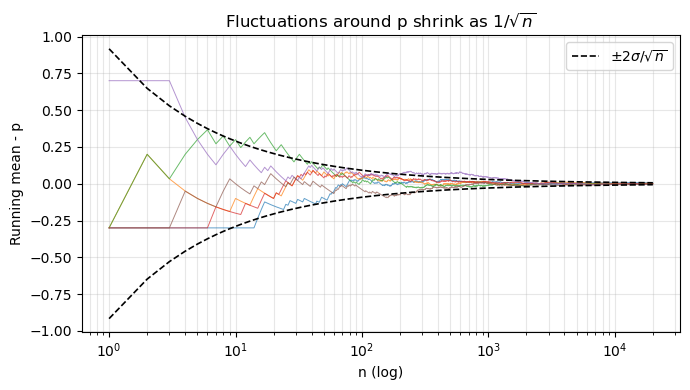

In [3]:
sigma = np.sqrt(p * (1 - p))
ns = np.arange(1, N + 1)
band = 2 * sigma / np.sqrt(ns)

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(n_paths):
    ax.plot(ns, running[i] - p, lw=0.7, alpha=0.7)
ax.plot(ns, band, "k--", lw=1.2, label=r"$\pm 2\sigma / \sqrt{n}$")
ax.plot(ns, -band, "k--", lw=1.2)
ax.set_xscale("log")
ax.set_xlabel("n (log)")
ax.set_ylabel("Running mean - p")
ax.set_title(r"Fluctuations around p shrink as $1/\sqrt{n}$")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. CLT: rescaled sum converges to $\mathcal{N}(0, 1)$

Let $S_n = X_1 + \dots + X_n$. Then
$Z_n = (S_n - n p) / \sqrt{n p (1 - p)} \xrightarrow{d} \mathcal{N}(0, 1)$.
Repeat the experiment $M = 20\,000$ times for each of several $n$ and
overlay the histogram with the standard normal density.

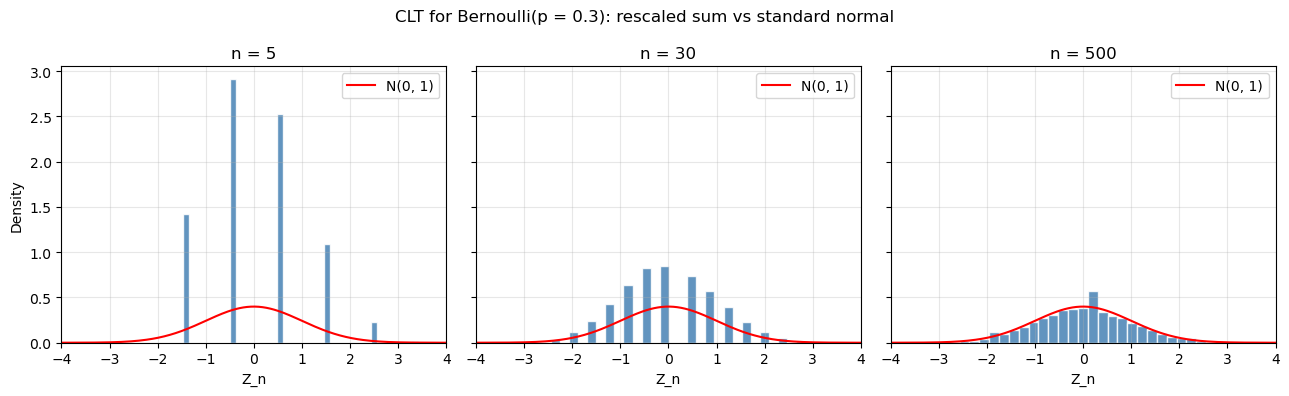

In [4]:
M = 20_000
n_grid = [5, 30, 500]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
xs = np.linspace(-4, 4, 200)
for ax, nv in zip(axes, n_grid):
    Sn = (np.random.uniform(size=(M, nv)) < p).sum(axis=1)
    Zn = (Sn - nv * p) / np.sqrt(nv * p * (1 - p))
    ax.hist(Zn, bins=40, density=True, color="steelblue",
            edgecolor="white", alpha=0.85)
    ax.plot(xs, norm.pdf(xs), "r-", lw=1.5, label="N(0, 1)")
    ax.set_title(f"n = {nv}")
    ax.set_xlabel("Z_n")
    ax.set_xlim(-4, 4)
    ax.legend()
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Density")
fig.suptitle(f"CLT for Bernoulli(p = {p}): rescaled sum vs standard normal")
plt.tight_layout()
plt.show()

## Exercises

1. Repeat the CLT panel with $p = 0.01$. For small $p$, the convergence is
   visibly slower (skewness is $1/\sqrt{n p (1-p)}$). Observe this.
2. Replace Bernoulli with Cauchy draws. The CLT fails because
   $\mathrm{Var}(X_1) = \infty$. Plot the histogram of $Z_n$ for
   $n = 500$ and describe what you see.
3. Estimate the Berry–Esseen constant empirically: compute
   $\sup_z |F_{Z_n}(z) - \Phi(z)|$ for a grid of $n$ and check whether it
   decays as $1/\sqrt{n}$.